In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import seaborn as sns 
from matplotlib.gridspec import GridSpec
import os

path = str(os.getcwd())
plots_dir = f"{path}/plots"
os.makedirs(plots_dir, exist_ok=True)

The current PMAT grouping is: 
- AT: PERI, ORB, ECT, TEa, AI, PFC (IL+PL), OLF
- PM: VISpor, RSP, PAR, PRE, PTLp, VIS, POST

# Heatmaps

n = 160 neurons
RSP: 58, RSP+ORB: 54, ORB: 48


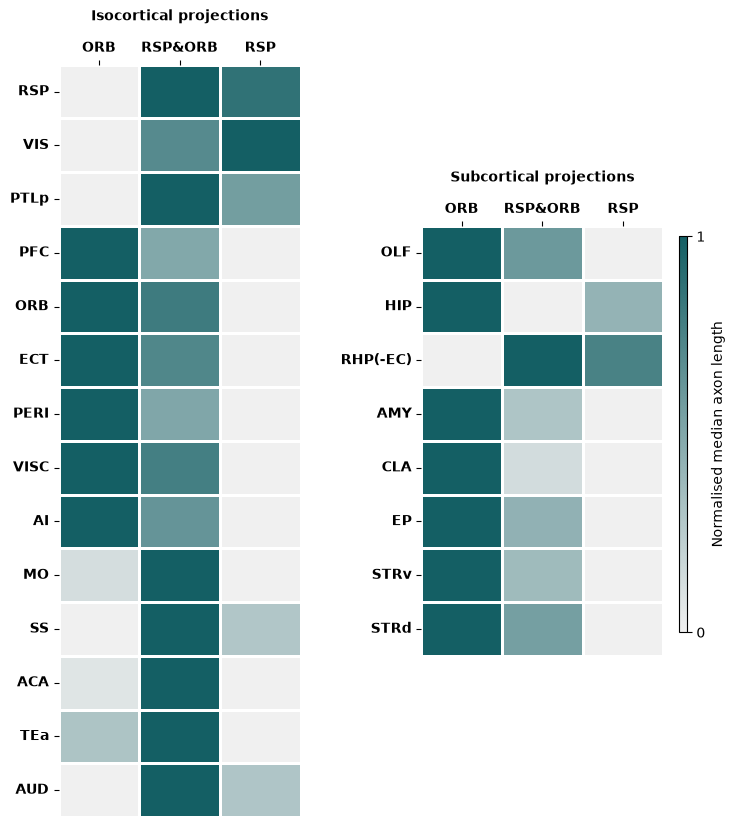

In [2]:

# Load the data
df_raw = pd.read_csv(path + '/preprocessed_data/master_detailed_comment.csv')
df_raw.columns = [str(c).strip() for c in df_raw.columns]

# Remove neurons that are unassgined due to bad tracing, positioning etc.
df = df_raw[df_raw['comment'].isna()].copy()
df['proj'] = df['proj'].replace('', np.nan).replace(r'^\s*$', np.nan, regex=True)
df = df.dropna(subset=['proj'])

# Convert all length columns to numeric, fill missing with 0
for col in [c for c in df_raw.columns if c.endswith('_length')]:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

# Prep data for plotting
plot_df = df.copy() 

print(f"n = {len(plot_df)} neurons")
print(f"RSP: {(plot_df['proj']=='rsp').sum()}, "
      f"RSP+ORB: {(plot_df['proj']=='rsp_orb').sum()}, "
      f"ORB: {(plot_df['proj']=='orb').sum()}")


plot_df["PFC_length"] = plot_df["PL_length"] + plot_df["ILA_length"]
plot_df["PFC_endpoint"] = plot_df["PL_endpoint"] + plot_df["ILA_endpoint"]

plot_df["AMY_length"] = plot_df["BLA_length"] + plot_df["LA_length"] +plot_df["BMA_length"] + plot_df["PA_length"]
plot_df["AMY_endpoint"] = plot_df["BLA_endpoint"] + plot_df["LA_endpoint"] +plot_df["BMA_endpoint"] + plot_df["PA_endpoint"]

# Define isocortical areas for plotting in Fig 5e
NEO_AREAS = [
    ('RSP_length',   'RSP',   'pm'),
    ('VIS_length',   'VIS',   'pm'),
    ('PTLp_length',  'PTLp',  'pm'),
    ('PFC_length',   'PFC',   'at'),
    ('ORB_length',   'ORB',   'at'),
    ('ECT_length',   'ECT',   'at'),
    ('PERI_length',  'PERI',  'at'),
    ('VISC_length',  'VISC',  'at'),
    ('AI_length',    'AI',    'at'),
    ('MO_length',    'MO',    'other'),
    ('SS_length',    'SS',    'other'),
    ('ACA_length',   'ACA',   'other'),
    ('TEa_length',   'TEa',   'at'),
    ('AUD_length',   'AUD',   'other'),
]

# Other areas for plotting in Fig 5f
OTHER_AREAS = [
    ('OLF_length',   'OLF',   'none'),
    ('HIP_length',   'HIP',   'none'),
    ('RHP(no_EC)_length',   'RHP(-EC)',   'none'),
    ('AMY_length',   'AMY',   'none'),
    ('CLA_length',   'CLA',   'none'),
    ('EP_length',    'EP',    'none'),
    ('STRv_length',  'STRv',  'none'),
    ('STRd_length',  'STRd',  'none'),
]

# Column order for the heatmap: ORB, RSC+ORB, RSC
GROUPS = [
    ('orb',     'ORB',       '#EA4FA2'),
    ('rsp_orb', 'RSC & ORB', '#FFD600'),
    ('rsp',     'RSC',       '#49A2C9'),
]

# Function for computing normalised medians per row
def compute_normalised_medians(areas, plot_df):
    """
    For each area, compute the median axon length per group,
    then normalise so 0 = lowest group median, 1 = highest group median.
    Also compute Kruskal-Wallis p-value for significance.

    Returns:
        norm_vals  : array (n_areas x n_groups) of normalised values 0-1
        sig_labels : list of significance strings per area
        labels     : list of display names per area
    """
    norm_vals  = []
    sig_labels = []
    labels     = []

    for col, lbl, grp in areas:
        if grp == 'gap':
            norm_vals.append([np.nan, np.nan, np.nan])
            sig_labels.append('')
            labels.append('')
            continue

        if col not in plot_df.columns:
            print(f"Warning: {col} not found, skipping")
            continue

        # Median per group
        meds = []
        vals_per_group = []
        for proj_val, _, _ in GROUPS:
            sub = plot_df[plot_df['proj'] == proj_val][col]
            meds.append(sub.median())
            vals_per_group.append(sub.values)

        # Normalise within row: 0=min, 1=max
        mn, mx = min(meds), max(meds)
        if mx > mn:
            norm = [(v - mn) / (mx - mn) for v in meds] # normalise to 0-1
        else:
            norm = [0.5, 0.5, 0.5]

        # Kruskal-Wallis significance
        h, p = stats.kruskal(*vals_per_group)
        sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))

        norm_vals.append(norm)
        sig_labels.append(sig)
        labels.append(lbl)

    return np.array(norm_vals), sig_labels, labels

# Call the function for both sets of areas
neo_norm,   neo_sig,   neo_labels   = compute_normalised_medians(NEO_AREAS,   plot_df)
other_norm, other_sig, other_labels = compute_normalised_medians(OTHER_AREAS, plot_df)

# Plot the heatmaps

PALETTE = 'teal'
cmap = LinearSegmentedColormap.from_list('teal', ['#f0f0f0', '#145f64'])

BAR_COL = '#888888'
cell_size = 0.8
fontsize = 10

neo_data = neo_norm
other_data = other_norm

n_rows_neo = neo_data.shape[1]
n_rows_other = other_data.shape[1]
n_cols = neo_data.shape[0]  # same for both (3 groups)

# figure width: two heatmaps + gap + colorbar space
fig_width = (n_rows_neo + n_rows_other) * cell_size + 3
fig_height = n_cols * cell_size + 2  # +2 for margins


fig = plt.figure(figsize=(fig_width, fig_height))

gs = GridSpec(1, 2,
              figure=fig,
              width_ratios=[n_rows_neo, n_rows_other],
              wspace=0.5)

ax_neo = fig.add_subplot(gs[0, 0])
ax_other = fig.add_subplot(gs[0, 1])

sns.heatmap(neo_data, ax=ax_neo, cmap=cmap,
            linewidths=2, linecolor='white',
            xticklabels=["ORB", "RSP&ORB", "RSP"],
            yticklabels=[area[1] for area in NEO_AREAS],
            vmin=0, vmax=1, square=False, cbar=False)

sns.heatmap(other_data, ax=ax_other, cmap=cmap,
            linewidths=2, linecolor='white',
            xticklabels=["ORB", "RSP&ORB", "RSP"],
            yticklabels=[area[1] for area in OTHER_AREAS],
            vmin=0, vmax=1, square=False, cbar=False)
cell_w = 0.8
cell_h = 1.2  # adjust ratio to taste

ax_neo.set_aspect(cell_w / cell_h)
ax_other.set_aspect(cell_w / cell_h)

# A small colourbar
ax_cbar = fig.add_axes([0.92, 0.35, 0.01, 0.3]) 

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
sm.set_array([])

fig.colorbar(sm, cax=ax_cbar, label="Normalised median axon length", ticks=[0, 1])
ax_cbar.tick_params(labelsize=fontsize)


for ax, title in [(ax_neo, "Isocortical projections"),
                  (ax_other, "Subcortical projections")]:
    ax.xaxis.set_ticks_position('top')
    ax.xaxis.set_label_position('top')
    ax.set_xticklabels(ax.get_xticklabels(), fontweight='bold', fontsize=fontsize, rotation=0)
    ax.set_ylabel('')
    ax.set_title(title, fontsize=fontsize, fontweight='bold', pad=15)

ax_neo.set_yticklabels(ax_neo.get_yticklabels(), fontweight='bold', fontsize=fontsize, rotation=0)
ax_other.set_yticklabels(ax_other.get_yticklabels(), fontweight='bold', fontsize=fontsize, rotation=0)


plt.savefig(path + "/plots/combined_heatmap.svg",
            dpi=300, bbox_inches='tight')
plt.show()

# Violin plots

/var/folders/nt/g3g_mp4d0cn2phh32qchfyf80000gn/T/ipykernel_5062/937598320.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/nt/g3g_mp4d0cn2phh32qchfyf80000gn/T/ipykernel_5062/937598320.py:50: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels, fontweight='bold')
/var/folders/nt/g3g_mp4d0cn2phh32qchfyf80000gn/T/ipykernel_5062/937598320.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/nt/g3g_mp4d0cn2phh32qchfyf80000gn/T/ipykernel_5062/937598320.py:50: UserWarning: set_ticklabels() should only be used with a fixed

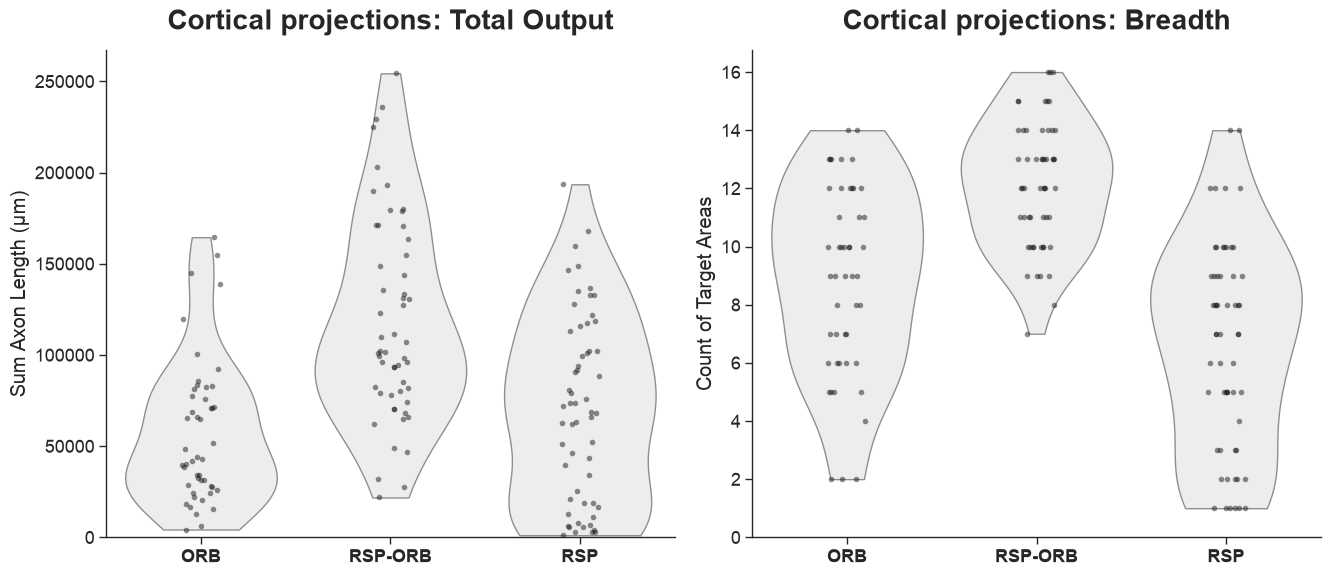

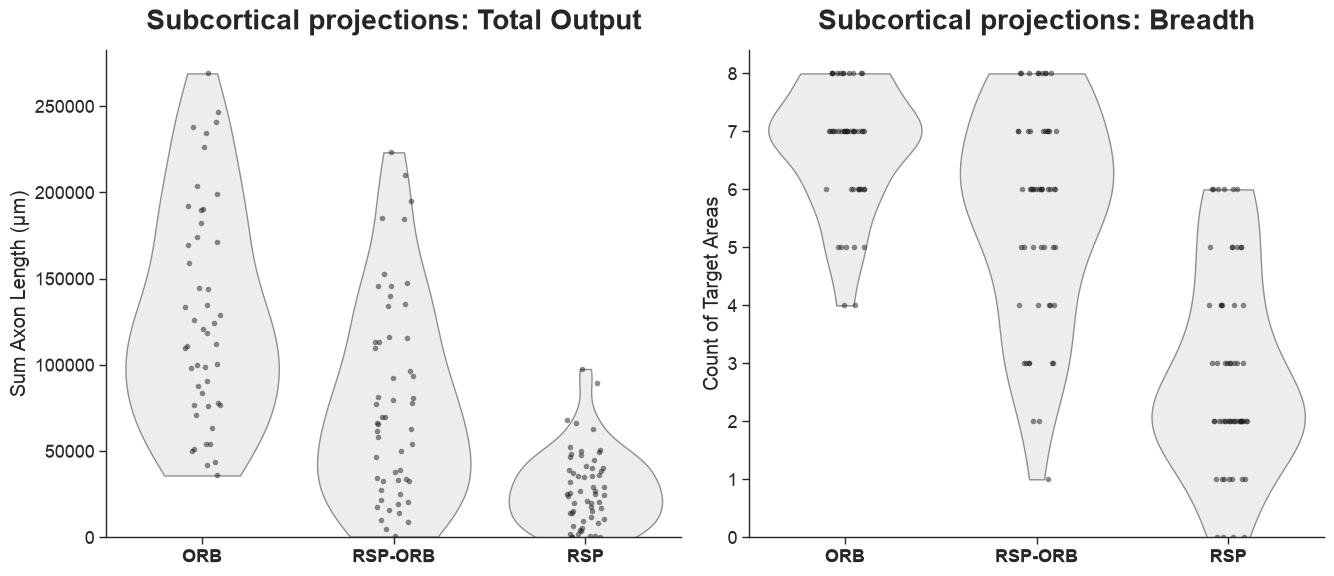

In [3]:

cortical_areas = ['PFC', 'ORB', 'AUD', 'TEa','ECT', 'PERI', 'VISC','AI', 'MO', 'SS', 'ACA', 'PTLp', 'VIS','VISpor', 'RSP', 'GU']
subcortical_areas = ["OLF", "HIP", "RHP(no_EC)","AMY","CLA","EP", "STRv", "STRd" ]

GROUPS = ['orb', 'rsp_orb', 'rsp']

CUSTOM_PALETTE = {
    'orb': "#EEEDED",       
    'rsp_orb': '#EEEDED',   
    'rsp': '#EEEDED'        
}


def plot_violin_metrics(df, areas, title_prefix,save_path):
    # 1. Calculate Metrics on the fly
    target_cols = [a + '_length' for a in areas if a + '_length' in df.columns]
    target_cols_endpoints = [a + '_endpoint' for a in areas if a + '_endpoint' in df.columns]

    # Total Length
    df['calc_total'] = df[target_cols].sum(axis=1)
    # Num Targets <- Need to decide on the treshold!!!!!!! for now keeping the old one
    df['calc_targets'] = (df[target_cols_endpoints] > 0).sum(axis=1)


    # 2. Plotting
    metrics = [
        ('calc_total', f'{title_prefix}: Total Output', 'Sum Axon Length (µm)'), #TOTAL IPSILATERAL OUTPUT
        ('calc_targets', f'{title_prefix}: Breadth', 'Count of Target Areas'), #BREADTH OF PROJECTIONS 
        ]

    plt.figure(figsize=(20, 6))
    sns.set_theme(font_scale=1.5, context="paper", style="white")
    sns.set_style("ticks")
    

    for i, (metric, title, ylabel) in enumerate(metrics):
        ax = plt.subplot(1, 3, i+1)
        sns.violinplot(
            x='proj', y=metric, data=df, order=GROUPS,
            palette=CUSTOM_PALETTE, inner=None, cut=0, ax=ax
        )
        sns.stripplot(
            x='proj', y=metric, data=df, order=GROUPS,
            color='k', alpha=0.5, size=4, jitter=True, ax=ax
        )
        ax.set_title(title, fontsize = 20, fontweight='bold', pad=15)
        ax.set_ylabel(ylabel)
        ax.set_xlabel('')
        # Format X labels
        labels = [g.upper().replace('_', '-') for g in GROUPS]
        ax.set_xticklabels(labels, fontweight='bold')
        ax.set_ylim(bottom=0)

    sns.despine()
    
    plt.tight_layout()
    #plt.show()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')

plot_violin_metrics(df_raw, cortical_areas, "Cortical projections", path + "/plots/violin_cortical.svg")
plot_violin_metrics(df_raw, subcortical_areas, "Subcortical projections", path + "/plots/violin_subcortical.svg")

# target_iso = [a + '_length' for a in cortical_areas if a + '_length' in master_list.columns] + ["calc_total","proj"]


In [4]:
import scikit_posthocs as sp

def run_stats(df, areas, label):
    
    d = df.copy()
    target_cols = [a + '_length' for a in areas if a + '_length' in d.columns]
    target_cols_endpoints = [a + '_endpoint' for a in areas if a + '_endpoint' in d.columns]
    d['calc_total'] = d[target_cols].sum(axis=1)
    d['calc_targets'] = (d[target_cols_endpoints] > 0).sum(axis=1)
    d = d[d['proj'].isin(GROUPS)]

    print(f"\n-{label}-")
    for metric, metric_label in [('calc_total', 'Total Output'), ('calc_targets', 'Breadth')]:
        vals_per_group = [d[d['proj'] == g][metric].values for g in GROUPS]
        h, p = stats.kruskal(*vals_per_group)
        print(f"\n{metric_label} — Kruskal-Wallis: H = {h:.3f}, p = {p:.4g}")

        posthoc = sp.posthoc_dunn(d, val_col=metric, group_col='proj', p_adjust='bonferroni')
        print("Dunn's post hoc (Bonferroni-corrected p-values):")
        print(posthoc.loc[GROUPS, GROUPS].to_string())


run_stats(df_raw, cortical_areas, "Cortical projections")
run_stats(df_raw, subcortical_areas, "Subcortical projections")



-Cortical projections-

Total Output — Kruskal-Wallis: H = 33.276, p = 5.947e-08
Dunn's post hoc (Bonferroni-corrected p-values):
                  orb       rsp_orb       rsp
orb      1.000000e+00  1.434702e-07  0.514216
rsp_orb  1.434702e-07  1.000000e+00  0.000048
rsp      5.142161e-01  4.775884e-05  1.000000

Breadth — Kruskal-Wallis: H = 61.083, p = 5.445e-14
Dunn's post hoc (Bonferroni-corrected p-values):
              orb       rsp_orb           rsp
orb      1.000000  1.029468e-05  1.535217e-02
rsp_orb  0.000010  1.000000e+00  2.558097e-14
rsp      0.015352  2.558097e-14  1.000000e+00

-Subcortical projections-

Total Output — Kruskal-Wallis: H = 73.970, p = 8.662e-17
Dunn's post hoc (Bonferroni-corrected p-values):
                  orb   rsp_orb           rsp
orb      1.000000e+00  0.000640  4.192170e-17
rsp_orb  6.397522e-04  1.000000  2.557179e-06
rsp      4.192170e-17  0.000003  1.000000e+00

Breadth — Kruskal-Wallis: H = 81.947, p = 1.605e-18
Dunn's post hoc (Bonferroni-